# Adversarial Attacks Against Deep Learning-Based Email Phishing Detection Model


This notebook demonstrates how to perform **adversarial attacks** against a deep learning model used for email phishing detection.  
We use **TextAttack** with the **DeepWordBugGao2018** attack recipe to generate adversarial email examples that can fool the classifier.


## 1. Import Required Libraries

We import:
- **TensorFlow/Keras** → Load and process the trained LSTM phishing detection model.  
- **Scikit-learn** → Encode labels and split datasets.  
- **TextAttack** → Generate adversarial examples.  
- **Matplotlib, Seaborn, Plotly** → Visualize attack results.


In [9]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import re
import textattack
from textattack.models.wrappers import ModelWrapper
from textattack.attack_recipes import DeepWordBugGao2018

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go


## 2. Data Preprocessing Function

This function cleans raw email text by:
- Removing links (URLs)
- Removing punctuation
- Converting text to lowercase
- Removing extra spaces

This ensures consistency between training and attack datasets.


In [10]:
def preprocess_text(text):
    text = re.sub(r'http\S+', '', text)  # Remove URLs
    text = re.sub(r'[^\w\s]', '', text)  # Remove punctuation
    text = text.lower()  # Lowercase text
    text = re.sub(r'\s+', ' ', text).strip()  # Remove extra spaces
    return text


## 3. Custom Model Wrapper for TextAttack

TextAttack requires a wrapper that:
- Converts raw text into token sequences
- Pads sequences to a fixed length
- Returns probabilities for **both classes**:
  - Class 0 → Safe Email
  - Class 1 → Phishing Email


In [11]:
class LSTMModelWrapper(ModelWrapper):
    def __init__(self, model, tokenizer, max_len=150):
        self.model = model
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __call__(self, text_list):
        sequences = self.tokenizer.texts_to_sequences(text_list)
        padded = pad_sequences(sequences, padding='post', maxlen=self.max_len)
        preds = self.model.predict(padded, verbose=0)
        return np.array([[1-p[0], p[0]] for p in preds])


## 4. Visualization of Attack Results

This function:
1. Calculates the **attack success rate**.
2. Shows the **distribution of queries** needed for successful vs. failed attacks.
3. Plots **original vs. perturbed scores** for successful adversarial examples.
4. Saves visualizations and successful examples to files.


In [18]:
def visualize_attack_results(log_file, successful_examples_file):
    df = pd.read_csv(log_file)

    # --- 1. Attack Success Rate ---
    success_rate = df["result_type"].value_counts(normalize=True).reset_index()
    success_rate.columns = ["Result Type", "Proportion"]

    plt.figure(figsize=(8, 6))
    sns.barplot(x="Result Type", y="Proportion", data=success_rate)
    plt.title("Attack Success Rate")
    plt.ylabel("Proportion")
    plt.xlabel("Result Type")
    plt.show()

    # --- 2. Distribution of Queries ---
    plt.figure(figsize=(10, 6))
    sns.histplot(data=df, x="num_queries", hue="result_type", kde=True, bins=20)
    plt.title("Distribution of Queries for Successful vs. Failed Attacks")
    plt.xlabel("Number of Queries")
    plt.ylabel("Count")
    plt.show()

    # --- 3. Original vs Perturbed Scores ---
    successful_attacks = df[df["result_type"] == "Successful"].copy()
    if not successful_attacks.empty:
        successful_attacks["original_score_percent"] = successful_attacks["original_score"] * 100
        successful_attacks["perturbed_score_percent"] = successful_attacks["perturbed_score"] * 100

        fig = px.scatter(
            successful_attacks,
            x="original_score_percent",
            y="perturbed_score_percent",
            title="Original Score vs. Perturbed Score (Successful Attacks)",
            labels={
                "original_score_percent": "Original Score (%)",
                "perturbed_score_percent": "Perturbed Score (%)"
            },
            hover_data={
                "original_text": True,
                "perturbed_text": True,
                "original_score": ":.4f",
                "perturbed_score": ":.4f",
                "ground_truth_output": True,
                "original_output": True,
                "perturbed_output": True
            }
        )
        fig.add_trace(go.Scatter(
            x=[0, 100], y=[0, 100],
            mode='lines',
            name='Identity Line',
            line=dict(color='gray', dash='dash')
        ))
        fig.show()

        successful_attacks.to_csv(successful_examples_file, index=False)
        print(f"✅ Saved successful adversarial examples to {successful_examples_file}")
    else:
        print("⚠ No successful attacks to visualize.")


## 5. Running the Adversarial Attack

Steps:
1. Load and preprocess phishing email dataset.
2. Encode labels as numeric values.
3. Tokenize and pad sequences.
4. Load trained LSTM phishing detection model.
5. Wrap the model for **TextAttack** compatibility.
6. Apply **DeepWordBugGao2018** adversarial attack.
7. Log and visualize results.


#### 📥 Load Data


In [19]:
data_file = r"C:\Users\USER\Ola_Adv_phishing\Data\raw\Phishing_Email.csv"

df = pd.read_csv(data_file)
df.drop(["Unnamed: 0"], axis=1, inplace=True)
df.dropna(inplace=True, axis=0)
df.drop_duplicates(inplace=True)

df["Email Text"] = df["Email Text"].apply(preprocess_text)


#### 🔢 Encode Labels and Tokenize


In [20]:
le = LabelEncoder()
df["Email Type"] = le.fit_transform(df["Email Type"])

tokenizer = Tokenizer()
tokenizer.fit_on_texts(df['Email Text'])
max_len = 150


#### 📂 Load Model


In [21]:
model_file = r"C:\Users\USER\Ola_Adv_phishing\models\lstm_email_classifier.h5"
model = tf.keras.models.load_model(model_file)


Compiled the loaded model, but the compiled metrics have yet to be built. `model.compile_metrics` will be empty until you train or evaluate the model.


#### Create Model Wrapper


In [22]:
model_wrapper = LSTMModelWrapper(model, tokenizer, max_len)


#### Prepare Dataset for TextAttack


In [23]:
dataset = textattack.datasets.Dataset(
    [(text, label) for text, label in zip(df['Email Text'], df['Email Type'])]
)


#### Define and Run the Attack


In [24]:
attack = DeepWordBugGao2018.build(model_wrapper)
attack_args = textattack.AttackArgs(
    num_examples=10,
    log_to_csv= r"C:\Users\USER\Ola_Adv_phishing\Data\adversary\attack_log.csv",
    log_to_txt= r"C:\Users\USER\Ola_Adv_phishing\Data\adversary\attack_log.txt",
    disable_stdout=True
)
attacker = textattack.Attacker(attack, dataset, attack_args)
attacker.attack_dataset()
print("✅ Attack completed. Results saved to attack_log.csv and attack_log.txt")


textattack: Unknown if model of class <class 'keras.src.models.sequential.Sequential'> compatible with goal function <class 'textattack.goal_functions.classification.untargeted_classification.UntargetedClassification'>.
textattack: Logging to text file at path C:\Users\USER\Ola_Adv_phishing\Data\adversary\attack_log.txt
textattack: Logging to CSV at path C:\Users\USER\Ola_Adv_phishing\Data\adversary\attack_log.csv


Attack(
  (search_method): GreedyWordSwapWIR(
    (wir_method):  unk
  )
  (goal_function):  UntargetedClassification
  (transformation):  CompositeTransformation(
    (0): WordSwapNeighboringCharacterSwap(
        (random_one):  True
      )
    (1): WordSwapRandomCharacterSubstitution(
        (random_one):  True
      )
    (2): WordSwapRandomCharacterDeletion(
        (random_one):  True
      )
    (3): WordSwapRandomCharacterInsertion(
        (random_one):  True
      )
    )
  (constraints): 
    (0): LevenshteinEditDistance(
        (max_edit_distance):  30
        (compare_against_original):  True
      )
    (1): RepeatModification
    (2): StopwordModification
  (is_black_box):  True
) 



[Succeeded / Failed / Skipped / Total] 3 / 7 / 0 / 10: 100%|███████████████████████████| 10/10 [11:57<00:00, 71.77s/it]


+-------------------------------+--------+
| Attack Results                |        |
+-------------------------------+--------+
| Number of successful attacks: | 3      |
| Number of failed attacks:     | 7      |
| Number of skipped attacks:    | 0      |
| Original accuracy:            | 100.0% |
| Accuracy under attack:        | 70.0%  |
| Attack success rate:          | 30.0%  |
| Average perturbed word %:     | 10.53% |
| Average num. words per input: | 276.0  |
| Avg num queries:              | 717.8  |
+-------------------------------+--------+
✅ Attack completed. Results saved to attack_log.csv and attack_log.txt


#### Visualize Attack Results


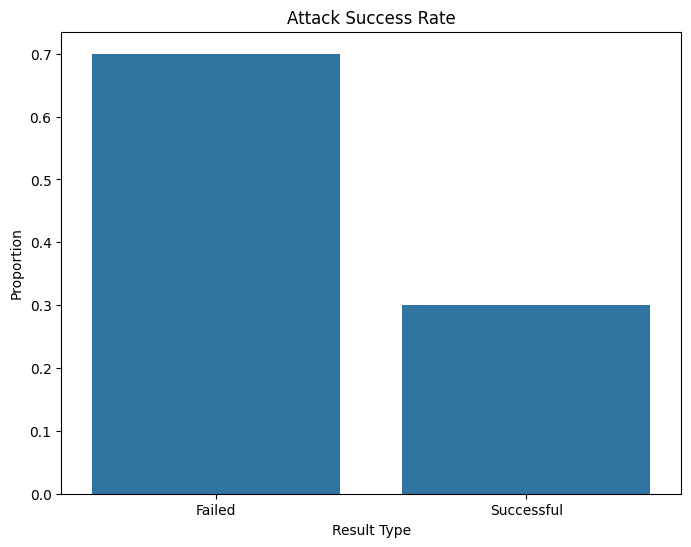

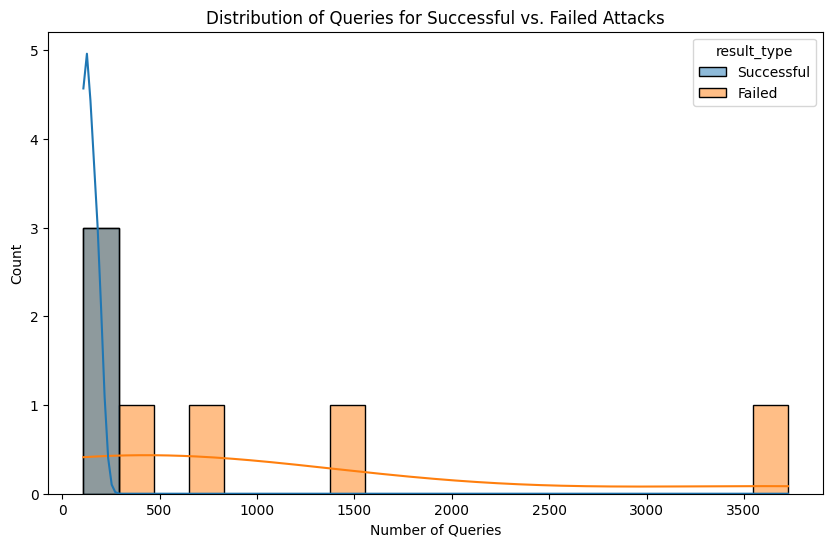

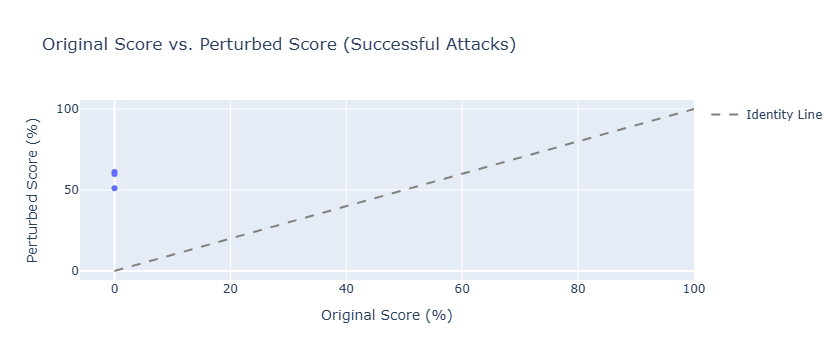

✅ Saved successful adversarial examples to C:\Users\USER\Ola_Adv_phishing\Data\adversary\successful_adversarial_examples.csv


In [25]:
visualize_attack_results(r"C:\Users\USER\Ola_Adv_phishing\Data\adversary\attack_log.csv", r"C:\Users\USER\Ola_Adv_phishing\Data\adversary\successful_adversarial_examples.csv")
